# 01 — UCI Maternal Health Risk: EDA, feature groups and locked split

**AIOVY thesis, UCI replication of the Mendeley pipeline.**

This notebook describes the deduplicated UCI dataset and fixes the
locked 20% test set that notebooks 02 and 03 reuse.

**Input:** `ml_model/uci/data/Maternal_Health_Risk_no_duplicates.csv`

**How the file was produced (before this notebook):**
the original UCI file has 1,014 rows but only 452 distinct rows. The
author's earlier cleaned file (`Maternal_Health_Risk_cleaned.csv`) kept
all 452 distinct rows plus a random half (281 rows, `random_state=42`)
of the 562 extra duplicate occurrences, then removed rows with
`HeartRate < 30` (an impossible heart rate of 7), leaving 732 rows.
The input used here removes the remaining exact duplicate rows from
that file (all 7 columns, first occurrence kept). That leaves
**451 rows**, each of them distinct. The earlier 732-row run is
archived in `ml_model/uci/archive_732_rows/`.

Removing exact duplicates does not remove *conflicting* rows: some
identical sets of measurements still appear with different risk
labels. Every split below is therefore still group-aware.

**Units:** `BS` in mmol/L and `BodyTemp` in °F, which are the app's
canonical units (`lib/models/maternal_indicators.dart`). No unit
conversion is applied. (The Mendeley pipeline converted temperature to
°C; that conversion is intentionally **not** reused.)

Nothing in this notebook removes or changes rows.

In [1]:
import sys
from pathlib import Path

# Make ml_model/uci importable whether the notebook runs from
# ml_model/uci/notebooks (default) or from ml_model/uci.
UCI_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "uci_common.py").exists())
sys.path.insert(0, str(UCI_DIR))

import uci_common as uc

print("Python:", sys.version.split()[0])
print("Interpreter:", sys.executable)
print("UCI folder:", UCI_DIR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit

uc.set_plot_style()
eda_dir = uc.REPORTS_DIR / "eda"
eda_dir.mkdir(parents=True, exist_ok=True)

Python: 3.12.10
Interpreter: C:\Users\Andrei PC\Desktop\Maternal\ThesisPrototype-main-updated\ml_model\uci\.venv\Scripts\python.exe
UCI folder: C:\Users\Andrei PC\Desktop\Maternal\ThesisPrototype-main-updated\ml_model\uci


## 1. Schema and missing values

In [2]:
df = uc.load_data()   # asserts 451 rows, expected columns, no missing values

print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isna().sum())
display(df.head())

Shape: (451, 7)

Data types:
Age              int64
SystolicBP       int64
DiastolicBP      int64
BS             float64
BodyTemp       float64
HeartRate        int64
RiskLevel          str
dtype: object

Missing values per column:
Age            0
SystolicBP     0
DiastolicBP    0
BS             0
BodyTemp       0
HeartRate      0
RiskLevel      0
dtype: int64


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


## 2. Class balance

,Records,Share
RiskLevel,,
low risk,233,51.7%
mid risk,106,23.5%
high risk,112,24.8%


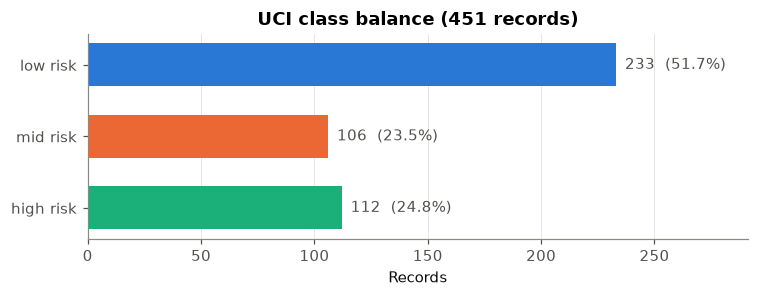

In [3]:
class_counts = (
    df[uc.TARGET].value_counts()
      .reindex(uc.CLINICAL_ORDER)
      .rename("Records")
      .to_frame()
)
class_counts["Share"] = class_counts["Records"] / len(df)
class_counts.index.name = "RiskLevel"
display(class_counts.style.format({"Share": "{:.1%}"}))

assert class_counts["Records"].to_dict() == {
    "low risk": 233, "mid risk": 106, "high risk": 112
}

class_counts.to_csv(eda_dir / "class_balance.csv")

fig, ax = plt.subplots(figsize=(7, 2.8))
bars = ax.barh(
    class_counts.index, class_counts["Records"],
    color=[uc.CLASS_COLORS[c] for c in class_counts.index], height=0.6,
)
for bar, (n, share) in zip(bars, class_counts.itertuples(index=False)):
    ax.text(bar.get_width() + 4, bar.get_y() + bar.get_height() / 2,
            f"{n}  ({share:.1%})", va="center", color="#52514e")
ax.invert_yaxis()
ax.set_xlabel("Records")
ax.set_xlim(0, class_counts["Records"].max() * 1.25)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.set_title(f"UCI class balance ({len(df)} records)")
fig.tight_layout()
fig.savefig(eda_dir / "class_balance.png", bbox_inches="tight")
plt.show()

## 3. Feature ranges

Ranges are shown with their units. The plausibility rules from the
Mendeley cleaning notebook (`02_eda_cleaning.ipynb`) are applied here
**for information only**, translated to °F, to show how this file would
fare under them. No rows are removed.

In [4]:
ranges = df[uc.FEATURES].describe().T
ranges.insert(0, "Unit", pd.Series(uc.FEATURE_UNITS))
ranges["Distinct values"] = df[uc.FEATURES].nunique()
display(ranges.round(2))
ranges.to_csv(eda_dir / "feature_ranges.csv")

print("BodyTemp value counts:")
print(df["BodyTemp"].value_counts().sort_index())

,Unit,count,mean,std,min,25%,50%,75%,max,Distinct values
Age,years,451.0,29.22,13.77,10.0,19.0,25.0,35.0,70.0,50
SystolicBP,mmHg,451.0,110.53,17.89,70.0,90.0,120.0,120.0,160.0,19
DiastolicBP,mmHg,451.0,75.42,13.77,49.0,65.0,80.0,87.0,100.0,16
BS,mmol/L,451.0,8.35,2.83,6.0,6.9,7.5,7.9,19.0,29
BodyTemp,degF,451.0,98.69,1.41,98.0,98.0,98.0,98.0,103.0,8
HeartRate,bpm,451.0,74.10,7.53,60.0,70.0,76.0,80.0,90.0,15


BodyTemp value counts:
BodyTemp
98.0     353
98.4       1
98.6       1
99.0       8
100.0      8
101.0     41
102.0     30
103.0      9
Name: count, dtype: int64


In [5]:
# Mendeley plausibility rules (02_eda_cleaning.ipynb), information only
plausibility = pd.DataFrame({
    "Age outside 10-60 (paper rule)": ~df["Age"].between(10, 60),
    "SystolicBP outside 60-250": ~df["SystolicBP"].between(60, 250),
    "DiastolicBP outside 30-150": ~df["DiastolicBP"].between(30, 150),
    "SystolicBP <= DiastolicBP": df["SystolicBP"] <= df["DiastolicBP"],
    "HeartRate outside 30-220": ~df["HeartRate"].between(30, 220),
    "BodyTemp outside 95-104 degF (paper rule)": ~df["BodyTemp"].between(95, 104),
})

plausibility_summary = plausibility.sum().rename("Flagged records").to_frame()
display(plausibility_summary)
plausibility_summary.to_csv(eda_dir / "plausibility_flags.csv")

print("Rows over age 60 by risk level:")
print(df.loc[df["Age"] > 60, uc.TARGET].value_counts())

,Flagged records
Age outside 10-60 (paper rule),7
SystolicBP outside 60-250,0
DiastolicBP outside 30-150,0
SystolicBP <= DiastolicBP,0
HeartRate outside 30-220,0
BodyTemp outside 95-104 degF (paper rule),0


Rows over age 60 by risk level:
RiskLevel
low risk     5
high risk    2
Name: count, dtype: int64


The rows over 60 years old would have been excluded by the Mendeley
"paper" age rule. They are kept here because the brief fixes the
cleaning of this file. This is recorded as a limitation in the
comparison report.

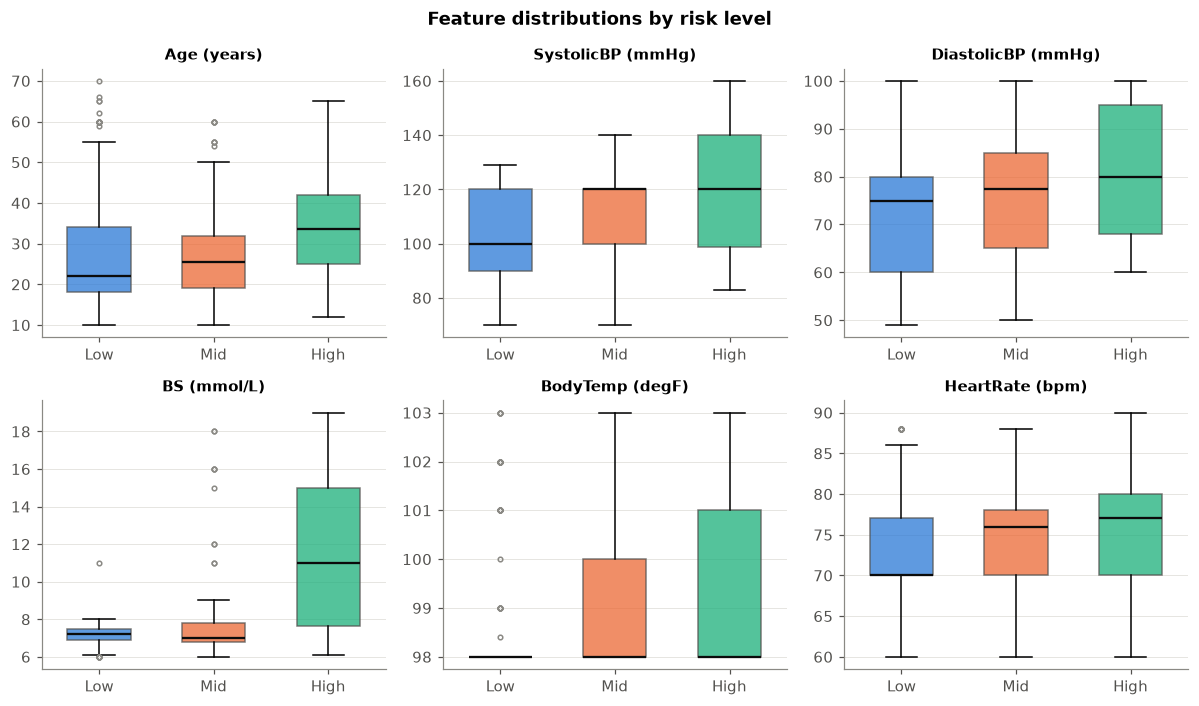

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))

for ax, feature in zip(axes.ravel(), uc.FEATURES):
    data = [df.loc[df[uc.TARGET] == c, feature] for c in uc.CLINICAL_ORDER]
    box = ax.boxplot(data, patch_artist=True, widths=0.55,
                     medianprops={"color": "#0b0b0b", "linewidth": 1.5},
                     flierprops={"markersize": 3, "markeredgecolor": "#8a8984"})
    for patch, c in zip(box["boxes"], uc.CLINICAL_ORDER):
        patch.set_facecolor(uc.CLASS_COLORS[c])
        patch.set_alpha(0.75)
        patch.set_edgecolor("#52514e")
    ax.set_xticks([1, 2, 3], ["Low", "Mid", "High"])
    ax.set_title(f"{feature} ({uc.FEATURE_UNITS[feature]})", fontsize=10)
    ax.grid(axis="x", visible=False)

fig.suptitle("Feature distributions by risk level", fontweight="bold")
fig.tight_layout()
fig.savefig(eda_dir / "feature_distributions_by_class.png", bbox_inches="tight")
plt.show()

## 4. Group IDs and conflicting labels

Group IDs follow the Mendeley notebooks exactly: one group per distinct
**six-feature vector** (`pd.util.hash_pandas_object(df[features])`).
Grouping on features only, not features plus label, is the stricter
choice. It guarantees that identical rows never fall on both sides of a
split. It also keeps rows with the *same measurements but different
labels* on the same side.

The input has no exact duplicate rows, so every group with more than
one record is a set of identical measurements with different labels.

In [7]:
group_ids = uc.make_group_ids(df)

n_rows = len(df)
n_distinct_rows = len(df.drop_duplicates())
n_feature_groups = group_ids.nunique()

group_summary = (
    df.assign(group_id=group_ids)
      .groupby("group_id")
      .agg(records=(uc.TARGET, "size"),
           distinct_labels=(uc.TARGET, "nunique"))
)

duplicate_overview = pd.Series({
    "Records": n_rows,
    "Exact duplicate rows (beyond first occurrence)": int(df.duplicated().sum()),
    "Distinct rows (feature + label)": n_distinct_rows,
    "Distinct feature vectors = groups": n_feature_groups,
    "Groups with more than one record": int((group_summary["records"] > 1).sum()),
    "Groups with conflicting labels": int((group_summary["distinct_labels"] > 1).sum()),
    "Records in conflicting-label groups": int(
        group_summary.loc[group_summary["distinct_labels"] > 1, "records"].sum()
    ),
    "Largest group size": int(group_summary["records"].max()),
}, name="Value").to_frame()

display(duplicate_overview)
duplicate_overview.to_csv(eda_dir / "duplicate_overview.csv")

assert n_distinct_rows == len(df) == 451   # no exact duplicate rows left
assert n_feature_groups == 415

print("Group size distribution (records per group):")
print(group_summary["records"].value_counts().sort_index().rename("Groups"))

,Value
Records,451
Exact duplicate rows (beyond first occurrence),0
Distinct rows (feature + label),451
Distinct feature vectors = groups,415
Groups with more than one record,35
Groups with conflicting labels,35
Records in conflicting-label groups,71
Largest group size,3


Group size distribution (records per group):
records
1    380
2     34
3      1
Name: Groups, dtype: int64


In [8]:
# Feature vectors that carry more than one label
conflicting = (
    df.assign(group_id=group_ids)
      .loc[lambda d: d["group_id"].isin(
          group_summary.index[group_summary["distinct_labels"] > 1])]
      .groupby(uc.FEATURES + [uc.TARGET])
      .size()
      .unstack(fill_value=0)
      .reindex(columns=uc.CLINICAL_ORDER, fill_value=0)
      .reset_index()
)
print("Conflicting-label feature vectors:", len(conflicting))
display(conflicting.head(10))
conflicting.to_csv(eda_dir / "conflicting_label_groups.csv", index=False)

print("\nLabel pairs involved:")
pairs = conflicting[uc.CLINICAL_ORDER].gt(0).apply(
    lambda r: " + ".join(c for c in uc.CLINICAL_ORDER if r[c]), axis=1)
print(pairs.value_counts())

Conflicting-label feature vectors: 35


RiskLevel,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,low risk,mid risk,high risk
0,12,90,60,7.5,102.0,66,1,1,0
1,12,95,60,6.9,98.0,65,1,1,0
2,13,90,65,7.5,101.0,80,1,0,1
3,15,120,80,7.5,98.0,70,1,1,0
4,16,100,70,6.9,98.0,80,1,1,0
5,17,85,60,9.0,102.0,86,0,1,1
6,17,90,65,7.5,103.0,67,1,1,0
7,18,90,60,6.9,98.0,70,1,1,0
8,19,120,75,6.9,98.0,66,1,1,0
9,19,120,80,7.0,98.0,70,1,1,0



Label pairs involved:
low risk + mid risk                24
low risk + high risk                5
mid risk + high risk                5
low risk + mid risk + high risk     1
Name: count, dtype: int64


In [9]:
# Descriptive in-sample accuracy ceiling (same check as Mendeley notebook 03):
# a model that sees identical features cannot separate conflicting labels.
counts = df.groupby(uc.FEATURES + [uc.TARGET]).size().unstack(fill_value=0)
best_possible = counts.max(axis=1).sum()

print(f"Descriptive in-sample accuracy ceiling: {best_possible / len(df):.2%}")
print("Minimum unavoidable mismatches:", len(df) - best_possible)

Descriptive in-sample accuracy ceiling: 92.02%
Minimum unavoidable mismatches: 36


## 5. Correlations

Spearman rank correlations between the six features and an ordinal
encoding of risk (low = 0, mid = 1, high = 2). The ordinal encoding is
used **only** here. The models use the fixed nominal label mapping
recorded in the config.

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskOrdinal
Age,1.00,0.45,0.42,0.26,-0.25,0.04,0.22
SystolicBP,0.45,1.00,0.77,0.22,-0.22,-0.03,0.31
DiastolicBP,0.42,0.77,1.00,0.21,-0.24,-0.04,0.22
BS,0.26,0.22,0.21,1.00,0.04,0.08,0.42
BodyTemp,-0.25,-0.22,-0.24,0.04,1.00,0.08,0.27
HeartRate,0.04,-0.03,-0.04,0.08,0.08,1.00,0.17
RiskOrdinal,0.22,0.31,0.22,0.42,0.27,0.17,1.00


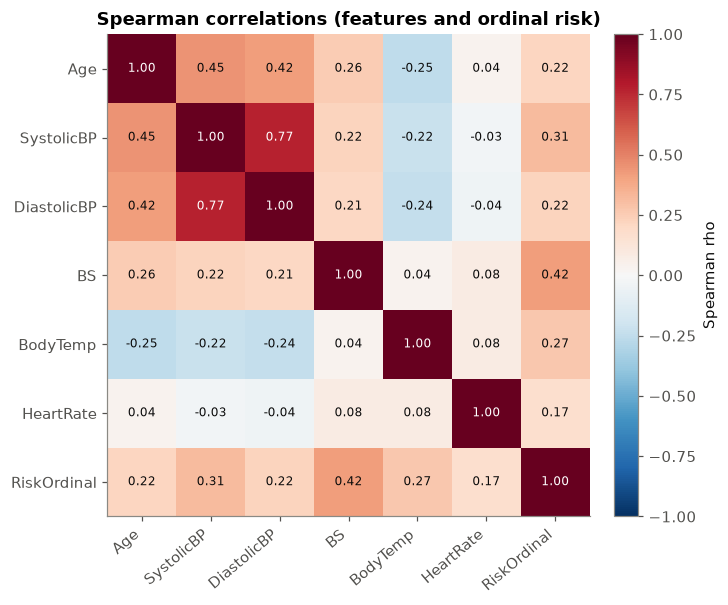

In [10]:
corr_df = df[uc.FEATURES].assign(
    RiskOrdinal=df[uc.TARGET].map({c: i for i, c in enumerate(uc.CLINICAL_ORDER)})
)
corr = corr_df.corr(method="spearman")
display(corr.round(2))
corr.to_csv(eda_dir / "spearman_correlations.csv")

fig, ax = plt.subplots(figsize=(6.8, 5.6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Spearman rho")
ax.set_title("Spearman correlations (features and ordinal risk)")
fig.tight_layout()
fig.savefig(eda_dir / "spearman_correlations.png", bbox_inches="tight")
plt.show()

## 6. Locked 20% test set

The Mendeley pipeline used `GroupShuffleSplit(test_size=0.20,
random_state=42)`, which is group-aware but **not** stratified. With
only 415 groups, an unstratified split can shift the class mix
noticeably. The brief asks for a split that is stratified as far as
groups allow. We therefore use `StratifiedGroupKFold(n_splits=5,
shuffle=True, random_state=42)` and take its first fold as the locked
test set (≈ 20%). This is the one deliberate departure from the
Mendeley split method. The GroupShuffleSplit result is shown alongside
for transparency.

The test set is not touched again until the final evaluation in
notebook 03.

In [11]:
train_idx, test_idx = uc.locked_split(df, group_ids)

train_groups = set(group_ids.iloc[train_idx])
test_groups = set(group_ids.iloc[test_idx])

print("Training records:", len(train_idx), f"({len(train_idx) / len(df):.1%})")
print("Locked test records:", len(test_idx), f"({len(test_idx) / len(df):.1%})")
print("Training groups:", len(train_groups))
print("Test groups:", len(test_groups))
print("Overlapping groups:", len(train_groups & test_groups))

assert len(train_groups & test_groups) == 0
assert len(train_idx) + len(test_idx) == len(df)
assert df[uc.TARGET].iloc[test_idx].nunique() == 3

Training records: 359 (79.6%)
Locked test records: 92 (20.4%)
Training groups: 332
Test groups: 83
Overlapping groups: 0


In [12]:
# Compare with the (unstratified) Mendeley split method
gss_train, gss_test = next(
    GroupShuffleSplit(n_splits=1, test_size=uc.TEST_SIZE,
                      random_state=uc.RANDOM_STATE)
    .split(df, groups=group_ids)
)

def distribution(idx):
    return df[uc.TARGET].iloc[idx].value_counts(normalize=True).reindex(uc.CLINICAL_ORDER)

split_distribution = pd.DataFrame({
    "Full data": distribution(np.arange(len(df))),
    "Train (locked split)": distribution(train_idx),
    "Test (locked split)": distribution(test_idx),
    "Test (GroupShuffleSplit, not used)": distribution(gss_test),
})
split_distribution.loc["records"] = [len(df), len(train_idx), len(test_idx), len(gss_test)]

display(split_distribution.style.format(
    lambda v: f"{v:.0f}" if v > 1 else f"{v:.1%}"))
split_distribution.to_csv(eda_dir / "split_class_distribution.csv")

,Full data,Train (locked split),Test (locked split),"Test (GroupShuffleSplit, not used)"
RiskLevel,,,,
low risk,51.7%,51.8%,51.1%,59.3%
mid risk,23.5%,23.4%,23.9%,20.9%
high risk,24.8%,24.8%,25.0%,19.8%
records,451,359,92,91


In [13]:
# Persist the assignment so notebooks 02 and 03 can verify they reproduce it
assignment = pd.DataFrame({
    "row_index": np.arange(len(df)),
    "group_id": group_ids.astype(str).to_numpy(),
    "RiskLevel": df[uc.TARGET].to_numpy(),
    "split": "train",
})
assignment.loc[test_idx, "split"] = "test"

assignment.to_csv(uc.REPORTS_DIR / "locked_split_assignment.csv", index=False)
print(assignment["split"].value_counts())
print("Saved:", uc.REPORTS_DIR / "locked_split_assignment.csv")

split
train    359
test      92
Name: count, dtype: int64
Saved: C:\Users\Andrei PC\Desktop\Maternal\ThesisPrototype-main-updated\ml_model\uci\reports\locked_split_assignment.csv


## Summary

* 451 records: 233 low, 106 mid and 112 high risk (51.7% / 23.5% / 24.8%).
  Low risk is about twice as common as each of the other classes. As in
  the Mendeley pipeline, SMOTE is not used.
* No exact duplicate rows remain, but there are only **415 distinct
  feature vectors**. 35 feature vectors (71 records) carry more than one
  risk label, mostly low and mid. This caps the achievable in-sample
  accuracy at **92.0%** (36 unavoidable mismatches).
* Group IDs are per six-feature vector, so conflicting-label twins never
  cross a split.
* `BodyTemp` is almost constant (353 of 451 records are 98 °F), and a few
  ages (7 records over 60) exceed the Mendeley 10–60 rule. Both are kept as documented
  limitations.
* Locked split: 359 training and 92 test records. They are
  group-disjoint, and the class mix matches the full data to within
  0.6 percentage points.